# Etapa 1: Carga, Visualización y Control de Calidad de Datos Sísmicos

Este notebook implementa el **Paso 1** del flujo de estimación de atenuación sísmica. Su objetivo es importar la información sísmica (formato SEG-Y o matrices de datos), estructurar el muestreo temporal y realizar controles de calidad geofísicos esenciales:

* Análisis de traza individual en amplitud y tiempo.
* Despliegue en *Wiggle* con relleno positivo para gathers y secciones sísmicas.
* Espectro de amplitud y potencia en decibelios (dB) para identificar la banda pasante.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

# Añadir la carpeta de módulos en Python al PATH
MODULE_DIR = os.path.abspath('../3_Python_Code')
if MODULE_DIR not in sys.path:
    sys.path.insert(0, MODULE_DIR)

from io_seismic import generate_synthetic_seismic_trace, save_mat_seismic
from config import SeismicSurveyConfig

print('Módulos importados correctamente.')

Módulos importados correctamente.


## 1. Definición de Parámetros y Carga de la Señal Sísmica

Definimos una configuración de levantamiento con una tasa de muestreo estándar de $\Delta t = 2\text{ ms}$ ($0.002\text{ s}$) y duración de $2.0\text{ s}$. Generamos una señal sísmica multicomponente con reflectores y atenuación.

In [2]:
survey_cfg = SeismicSurveyConfig(
    survey_name='Seismic_Survey_Area',
    line_name='Seismic_Line_01',
    well_name='Well_01',
    sample_rate_s=0.002,
    t_max_s=2.0
)

# Generamos una traza sísmica con reflectores y factor Q = 60
t_vec, main_trace = generate_synthetic_seismic_trace(
    sample_rate_s=survey_cfg.sample_rate_s,
    t_max_s=survey_cfg.t_max_s,
    peak_frequencies=(25.0, 38.0, 50.0),
    arrival_times_s=(0.35, 0.85, 1.35),
    amplitudes=(1.0, 0.72, 0.48),
    true_q=60.0,
    noise_level=0.015,
    random_seed=42
)

# Generamos un gather sísmico sintético de 15 trazas adyacentes
n_traces = 15
gather = np.zeros((len(t_vec), n_traces))
for i in range(n_traces):
    offset_factor = 1.0 - 0.015 * abs(i - n_traces // 2)
    jitter = np.random.normal(0, 0.01, size=len(t_vec))
    gather[:, i] = main_trace * offset_factor + jitter

print(f'Traza principal: {len(main_trace)} muestras.')
print(f'Gather sísmico: {gather.shape[1]} trazas x {gather.shape[0]} muestras.')

Traza principal: 1001 muestras.
Gather sísmico: 15 trazas x 1001 muestras.


## 2. Visualización y Control de Calidad (QC)

Generamos los gráficos clásicos del procesamiento sísmico:

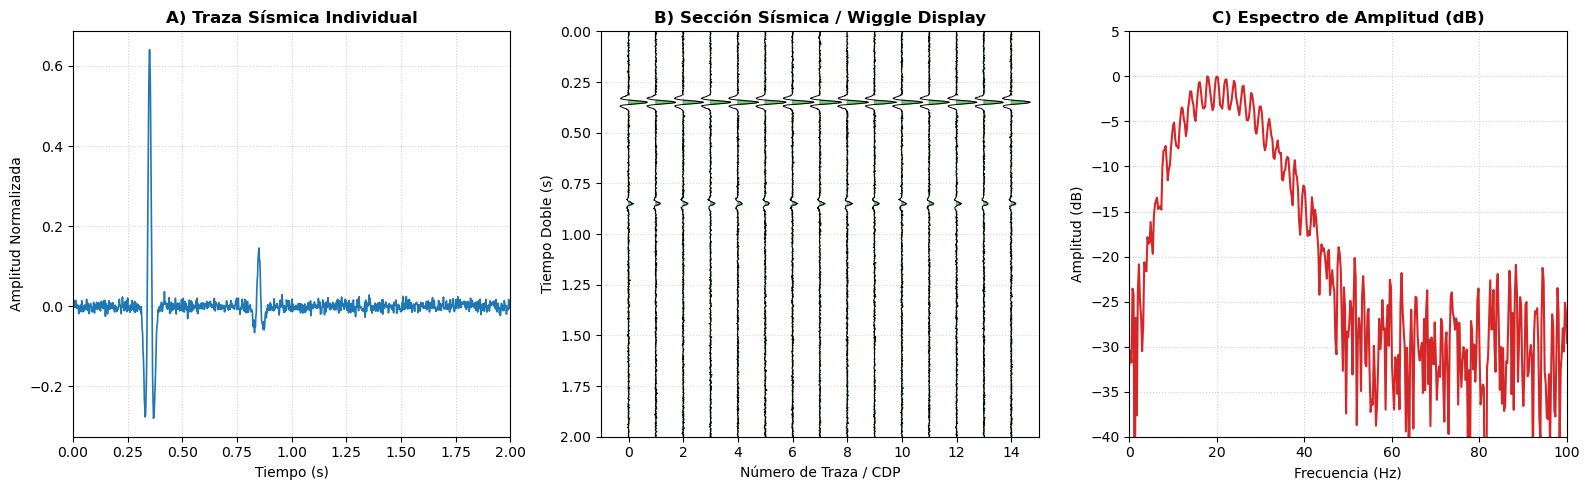

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: Traza individual
axes[0].plot(t_vec, main_trace, color='#1f77b4', linewidth=1.2)
axes[0].set_title('A) Traza Sísmica Individual', fontweight='bold')
axes[0].set_xlabel('Tiempo (s)')
axes[0].set_ylabel('Amplitud Normalizada')
axes[0].set_xlim(0, 2.0)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel 2: Despliegue en Wiggle
scale = 0.8
for i in range(n_traces):
    tr = gather[:, i]
    tr_norm = tr / np.max(np.abs(gather)) * scale
    axes[1].plot(i + tr_norm, t_vec, color='black', linewidth=0.7)
    axes[1].fill_betweenx(t_vec, i, i + tr_norm, where=(tr_norm > 0), color='#2ca02c', alpha=0.6)
axes[1].set_title('B) Sección Sísmica / Wiggle Display', fontweight='bold')
axes[1].set_xlabel('Número de Traza / CDP')
axes[1].set_ylabel('Tiempo Doble (s)')
axes[1].set_ylim(2.0, 0)  # Invertir eje de tiempo
axes[1].set_xlim(-1, n_traces)
axes[1].grid(True, linestyle=':', alpha=0.5)

# Panel 3: Espectro de amplitud
n_fft = 2048
fft_vals = np.abs(np.fft.rfft(main_trace, n=n_fft))
freqs = np.fft.rfftfreq(n_fft, d=survey_cfg.sample_rate_s)
fft_db = 20 * np.log10(fft_vals / np.max(fft_vals) + 1e-6)
axes[2].plot(freqs, fft_db, color='#d62728', linewidth=1.5)
axes[2].set_title('C) Espectro de Amplitud (dB)', fontweight='bold')
axes[2].set_xlabel('Frecuencia (Hz)')
axes[2].set_ylabel('Amplitud (dB)')
axes[2].set_xlim(0, 100)
axes[2].set_ylim(-40, 5)
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## 3. Exportación de Datos para la Etapa de Descomposición

Guardamos la traza procesada y sus metadatos en un archivo `.mat` y `.npz` para que puedan ser cargados por los siguientes notebooks.

In [4]:
os.makedirs('data_processed', exist_ok=True)
save_mat_seismic(
    'data_processed/traza_preprocesada.mat',
    {'trace': main_trace, 'time': t_vec, 'dt': survey_cfg.sample_rate_s}
)
np.savez('data_processed/traza_preprocesada.npz', trace=main_trace, time=t_vec, dt=survey_cfg.sample_rate_s)
print('Datos exportados exitosamente a data_processed/traza_preprocesada.mat y .npz')

Datos exportados exitosamente a data_processed/traza_preprocesada.mat y .npz
